# Phase 1: Dual-Task LSTM Temporal Encoder (Mortality & Sepsis)

This notebook trains the multi-task temporal LSTM encoder, evaluates **In-Hospital Mortality** and **ICU Sepsis** prediction performance on held-out test hospitals, displays comprehensive side-by-side comparative metrics & diagnostic plots, and exports 64-dimensional patient embeddings.

**Cohort Structure (Hospital-level split)**:
- Train: 144 hospitals (153,831 patients)
- Validation: 31 hospitals (24,186 patients)
- Test: 32 hospitals (22,809 patients)

**Key Capabilities**:
1. **Sub-second fast caching**: Loads pre-aligned 48-hour temporal sequences and dual labels via `ICUSequenceDataset(include_sepsis=True, use_cache=True)`.
2. **Dual-Head Multi-Task Architecture**: Jointly optimizes mortality and sepsis BCE objectives with class-weighted loss terms.
3. **Independent Threshold Calibration**: Calibrates optimal decision thresholds on the validation set ($F_1$ for mortality, $F_2$ for clinical sepsis sensitivity).
4. **Side-by-side Comparative Display**: Renders test evaluation metrics in a formatted table and publication-quality diagnostic plots (Confusion Matrices, ROC, PR curves).
5. **Temporal Embedding Export**: Exports 64-d temporal embeddings and patient unit IDs for multimodal fusion.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import copy
import json
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Resilient project root resolution (works from root or subfolders)
_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [_start, *_start.parents] if (p / "checkpoints").exists() and (p / "processed").exists()),
    _start,
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.dataset import ICUSequenceDataset, get_hospital_splits
from src.models.architecture import TemporalEncoder

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
PATIENCE = 3
LR = 5e-4
LSTM_HIDDEN = 120
EMB_DIM = 64
DROPOUT = 0.238

PROCESSED_ROOT = PROJECT_ROOT / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_ROOT / "checkpoints"
OUT_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

device = get_device()
print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_ROOT)
print("Output directory:", OUT_DIR)
print("Device:", device)


Project root: /Users/aryandwivedi/Desktop/Project Hail Minor
Processed data: /Users/aryandwivedi/Desktop/Project Hail Minor/processed
Output directory: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints
Device: mps


## 2. Load hospital splits and multi-task datasets

In [2]:
def load_dataset(name, hospital_dirs, return_pid=True):
    start = perf_counter()
    print(f"\nLoading {name} dataset...")

    ds = ICUSequenceDataset(
        hospital_dirs,
        return_pid=return_pid,
        include_sepsis=True,
        use_cache=True,
    )

    elapsed = perf_counter() - start
    print(
        f"{name}: {len(ds):,} patients loaded "
        f"in {elapsed:.2f} seconds"
    )
    return ds


# 1. Split hospitals
train_dirs, val_dirs, test_dirs = get_hospital_splits(
    str(PROCESSED_ROOT)
)

print(
    f"Hospitals: train={len(train_dirs)}, "
    f"val={len(val_dirs)}, test={len(test_dirs)}"
)


# 2. Load each dataset ONCE, including patient IDs and sepsis labels
train_ds = load_dataset("Train", train_dirs)
val_ds = load_dataset("Validation", val_dirs)
test_ds = load_dataset("Test", test_dirs)

print(
    f"\nPatients: train={len(train_ds):,}, "
    f"val={len(val_ds):,}, test={len(test_ds):,}"
)

# 3. Print outcome prevalence stats
for split_name, ds in [("Train", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
    n_tot = len(ds)
    n_mort = sum(int(s[2]) for s in ds.samples)
    n_seps = sum(int(s[3]) for s in ds.samples)
    print(
        f"  {split_name:10s}: Mortality={n_mort:,} ({n_mort/n_tot*100:.2f}%), "
        f"Sepsis={n_seps:,} ({n_seps/n_tot*100:.2f}%)"
    )

# 4. DataLoaders for model training and evaluation
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 5. DataLoaders for embedding extraction
train_embed_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

val_embed_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_embed_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nAll multi-task datasets and DataLoaders are ready.")


Hospitals: train=144, val=31, test=32

Loading Train dataset...
Train: 153,831 patients loaded in 0.28 seconds

Loading Validation dataset...
Validation: 24,186 patients loaded in 0.05 seconds

Loading Test dataset...
Test: 22,809 patients loaded in 0.05 seconds

Patients: train=153,831, val=24,186, test=22,809
  Train     : Mortality=13,634 (8.86%), Sepsis=24,477 (15.91%)
  Validation: Mortality=2,289 (9.46%), Sepsis=3,919 (16.20%)
  Test      : Mortality=2,081 (9.12%), Sepsis=3,746 (16.42%)

All multi-task datasets and DataLoaders are ready.


## 3. Configure dual-task class weighting and model

In [3]:
train_mort_labels = np.asarray([sample[2] for sample in train_ds.samples])
train_seps_labels = np.asarray([sample[3] for sample in train_ds.samples])

n_mort_pos = int((train_mort_labels == 1).sum())
n_mort_neg = int((train_mort_labels == 0).sum())
pos_weight_mort = torch.tensor(n_mort_neg / max(n_mort_pos, 1), dtype=torch.float32)

n_seps_pos = int((train_seps_labels == 1).sum())
n_seps_neg = int((train_seps_labels == 0).sum())
pos_weight_seps = torch.tensor(n_seps_neg / max(n_seps_pos, 1), dtype=torch.float32)

criterion_mort = nn.BCEWithLogitsLoss(pos_weight=pos_weight_mort.to(device))
criterion_seps = nn.BCEWithLogitsLoss(pos_weight=pos_weight_seps.to(device))

model = TemporalEncoder(
    input_size=92,
    lstm_hidden=LSTM_HIDDEN,
    emb_dim=EMB_DIM,
    dropout=DROPOUT,
    use_sepsis_head=True,
).to(device)

# Optionally warm-start backbone weights from existing checkpoint if available
ckpt_path = OUT_DIR / "lstm_temporal_encoder.pt"
if ckpt_path.exists():
    try:
        old_state = torch.load(ckpt_path, map_location=device)
        missing, unexpected = model.load_state_dict(old_state, strict=False)
        print(f"Loaded weights from {ckpt_path} (newly initialized: {missing})")
    except Exception as e:
        print(f"Note on warm-start: {e}")

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print(f"Mortality Cases: pos={n_mort_pos:,}, neg={n_mort_neg:,}, pos_weight={pos_weight_mort.item():.4f}")
print(f"Sepsis Cases:    pos={n_seps_pos:,}, neg={n_seps_neg:,}, pos_weight={pos_weight_seps.item():.4f}")
print("\nDual-Task Temporal Model Architecture:")
print(model)


Loaded weights from /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/lstm_temporal_encoder.pt (newly initialized: [])
Mortality Cases: pos=13,634, neg=140,197, pos_weight=10.2829
Sepsis Cases:    pos=24,477, neg=129,354, pos_weight=5.2847

Dual-Task Temporal Model Architecture:
TemporalEncoder(
  (lstm): LSTM(92, 120, batch_first=True)
  (dropout): Dropout(p=0.238, inplace=False)
  (proj): Sequential(
    (0): Linear(in_features=120, out_features=64, bias=True)
    (1): ReLU()
  )
  (head): Linear(in_features=64, out_features=1, bias=True)
  (sepsis_head): Linear(in_features=64, out_features=1, bias=True)
)


## 4. Multi-task training and evaluation helpers

In [4]:
def run_epoch(model, loader, criterion_mort, criterion_seps, device, optimizer=None, return_preds=False):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_loss_mort = 0.0
    total_loss_seps = 0.0

    all_mort_probs, all_mort_labels = [], []
    all_seps_probs, all_seps_labels = [], []

    for batch in loader:
        x, mask, y_mort, y_seps = batch[0], batch[1], batch[2], batch[3]
        x = x.to(device)
        mask = mask.to(device)
        y_mort = y_mort.to(device).float().view(-1)
        y_seps = y_seps.to(device).float().view(-1)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            mort_logits, seps_logits = model(x, mask)
            mort_logits = mort_logits.view(-1)
            seps_logits = seps_logits.view(-1)

            loss_mort = criterion_mort(mort_logits, y_mort)
            loss_seps = criterion_seps(seps_logits, y_seps)
            loss = loss_mort + loss_seps

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        mort_prob = torch.sigmoid(mort_logits)
        seps_prob = torch.sigmoid(seps_logits)

        b_size = len(y_mort)
        total_loss += loss.item() * b_size
        total_loss_mort += loss_mort.item() * b_size
        total_loss_seps += loss_seps.item() * b_size

        all_mort_probs.extend(mort_prob.detach().cpu().numpy().tolist())
        all_mort_labels.extend(y_mort.detach().cpu().numpy().tolist())
        all_seps_probs.extend(seps_prob.detach().cpu().numpy().tolist())
        all_seps_labels.extend(y_seps.detach().cpu().numpy().tolist())

    n_samples = max(len(loader.dataset), 1)
    avg_loss = total_loss / n_samples
    avg_loss_mort = total_loss_mort / n_samples
    avg_loss_seps = total_loss_seps / n_samples

    all_mort_labels = np.asarray(all_mort_labels)
    all_mort_probs = np.asarray(all_mort_probs)
    all_seps_labels = np.asarray(all_seps_labels)
    all_seps_probs = np.asarray(all_seps_probs)

    mort_auc = roc_auc_score(all_mort_labels, all_mort_probs) if len(np.unique(all_mort_labels)) == 2 else float("nan")
    mort_ap = average_precision_score(all_mort_labels, all_mort_probs) if np.sum(all_mort_labels) > 0 else float("nan")

    seps_auc = roc_auc_score(all_seps_labels, all_seps_probs) if len(np.unique(all_seps_labels)) == 2 else float("nan")
    seps_ap = average_precision_score(all_seps_labels, all_seps_probs) if np.sum(all_seps_labels) > 0 else float("nan")

    metrics_dict = {
        "loss": avg_loss,
        "loss_mort": avg_loss_mort,
        "loss_seps": avg_loss_seps,
        "mort_auc": mort_auc,
        "mort_ap": mort_ap,
        "seps_auc": seps_auc,
        "seps_ap": seps_ap,
        "mean_ap": (mort_ap + seps_ap) / 2.0 if np.isfinite(mort_ap) and np.isfinite(seps_ap) else float("nan"),
    }

    if return_preds:
        return metrics_dict, (all_mort_labels, all_mort_probs), (all_seps_labels, all_seps_probs)
    return metrics_dict


## 5. Train the Multi-Task LSTM

In [5]:
epoch_times = []
training_start = perf_counter()

best_mean_ap = -np.inf
best_state = None
wait = 0
history = []

for epoch in range(MAX_EPOCHS):
    epoch_start = perf_counter()

    train_m = run_epoch(
        model, train_loader, criterion_mort, criterion_seps, device, optimizer=optimizer
    )
    val_m = run_epoch(
        model, val_loader, criterion_mort, criterion_seps, device
    )

    epoch_elapsed = perf_counter() - epoch_start
    epoch_times.append(epoch_elapsed)

    elapsed = perf_counter() - training_start
    avg_epoch_time = sum(epoch_times) / len(epoch_times)
    remaining = avg_epoch_time * (MAX_EPOCHS - epoch - 1)

    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": train_m["loss"],
        "train_loss_mort": train_m["loss_mort"],
        "train_loss_seps": train_m["loss_seps"],
        "train_mort_auc": train_m["mort_auc"],
        "train_mort_ap": train_m["mort_ap"],
        "train_seps_auc": train_m["seps_auc"],
        "train_seps_ap": train_m["seps_ap"],
        "val_loss": val_m["loss"],
        "val_loss_mort": val_m["loss_mort"],
        "val_loss_seps": val_m["loss_seps"],
        "val_mort_auc": val_m["mort_auc"],
        "val_mort_ap": val_m["mort_ap"],
        "val_seps_auc": val_m["seps_auc"],
        "val_seps_ap": val_m["seps_ap"],
        "val_mean_ap": val_m["mean_ap"],
        "epoch_seconds": epoch_elapsed,
    }
    history.append(epoch_record)

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss={train_m['loss']:.4f} (Mort={train_m['loss_mort']:.4f}, Seps={train_m['loss_seps']:.4f}) | "
        f"Val Loss={val_m['loss']:.4f}\n"
        f"       Mortality: Val AUROC={val_m['mort_auc']:.4f}, Val AUPRC={val_m['mort_ap']:.4f} | "
        f"Sepsis: Val AUROC={val_m['seps_auc']:.4f}, Val AUPRC={val_m['seps_ap']:.4f} | "
        f"Mean AUPRC={val_m['mean_ap']:.4f}"
    )

    print(
        f"       Epoch time: {epoch_elapsed:.1f}s | "
        f"Elapsed: {elapsed / 60:.2f} min | "
        f"Estimated remaining: {remaining / 60:.2f} min"
    )

    if np.isfinite(val_m["mean_ap"]) and val_m["mean_ap"] > best_mean_ap:
        best_mean_ap = val_m["mean_ap"]
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

if best_state is None:
    raise RuntimeError(
        "No valid model checkpoint selected. Check that the validation set "
        "contains positive examples and the data loaded correctly."
    )

model.load_state_dict(best_state)

checkpoint_path = OUT_DIR / "lstm_temporal_encoder.pt"
torch.save(model.state_dict(), checkpoint_path)
print(f"Saved best multi-task checkpoint: {checkpoint_path}")


Epoch 01/10 | Train Loss=1.4786 (Mort=0.7574, Seps=0.7212) | Val Loss=1.6881
       Mortality: Val AUROC=0.8526, Val AUPRC=0.4762 | Sepsis: Val AUROC=0.8661, Val AUPRC=0.5850 | Mean AUPRC=0.5306
       Epoch time: 9.4s | Elapsed: 0.16 min | Estimated remaining: 1.41 min
Epoch 02/10 | Train Loss=1.4705 (Mort=0.7519, Seps=0.7186) | Val Loss=1.7023
       Mortality: Val AUROC=0.8510, Val AUPRC=0.4747 | Sepsis: Val AUROC=0.8644, Val AUPRC=0.5831 | Mean AUPRC=0.5289
       Epoch time: 11.2s | Elapsed: 0.34 min | Estimated remaining: 1.37 min
Epoch 03/10 | Train Loss=1.4552 (Mort=0.7436, Seps=0.7116) | Val Loss=1.7298
       Mortality: Val AUROC=0.8507, Val AUPRC=0.4704 | Sepsis: Val AUROC=0.8638, Val AUPRC=0.5837 | Mean AUPRC=0.5271
       Epoch time: 6.5s | Elapsed: 0.45 min | Estimated remaining: 1.05 min
Epoch 04/10 | Train Loss=1.4361 (Mort=0.7330, Seps=0.7031) | Val Loss=1.7195
       Mortality: Val AUROC=0.8490, Val AUPRC=0.4715 | Sepsis: Val AUROC=0.8652, Val AUPRC=0.5859 | Mean AUPR

In [6]:
with open(OUT_DIR / "training_history.json", "w") as f:
    json.dump(history, f, indent=2, allow_nan=True)

print(f"Total training time: {(perf_counter() - training_start) / 60:.2f} min")
print("Saved best checkpoint:", checkpoint_path)


Total training time: 0.56 min
Saved best checkpoint: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/lstm_temporal_encoder.pt


In [7]:
# 1. Get probabilities from the VALIDATION set for both tasks
val_m, (y_val_mort, val_prob_mort), (y_val_seps, val_prob_seps) = run_epoch(
    model, val_loader, criterion_mort, criterion_seps, device, return_preds=True
)

def find_best_threshold(y_true, y_prob, metric="f1", beta=1.0):
    best_thresh = 0.5
    best_score = -1.0
    records = []

    for threshold in np.arange(0.01, 1.00, 0.01):
        y_pred = (y_prob >= threshold).astype(int)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        acc = accuracy_score(y_true, y_pred)
        bal_acc = balanced_accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        f_beta = ((1 + beta**2) * prec * rec) / (beta**2 * prec + rec) if (beta**2 * prec + rec) > 0 else 0.0

        records.append({
            "threshold": round(float(threshold), 2),
            "F1": f1,
            "F_beta": f_beta,
            "Precision": prec,
            "Recall": rec,
            "Accuracy": acc,
            "Balanced_accuracy": bal_acc,
        })
        score_val = f_beta if metric == "fbeta" else f1
        if score_val > best_score:
            best_score = score_val
            best_thresh = round(float(threshold), 2)

    return best_thresh, pd.DataFrame(records)

# Calibrate optimal decision thresholds independently on the validation set
best_thresh_mort, mort_val_df = find_best_threshold(y_val_mort, val_prob_mort, metric="f1")
best_thresh_seps, seps_val_df = find_best_threshold(y_val_seps, val_prob_seps, metric="fbeta", beta=2.0)

print(f"Optimal Validation Thresholds:")
print(f"  - Mortality: threshold = {best_thresh_mort:.2f} (optimizing F1)")
print(f"  - Sepsis:    threshold = {best_thresh_seps:.2f} (optimizing F2 for clinical early warning)")

print("\n--- Mortality Validation Metrics (Top 5 Thresholds by F1) ---")
print(mort_val_df.sort_values("F1", ascending=False).head(5).to_string(index=False))

print("\n--- Sepsis Validation Metrics (Top 5 Thresholds by F_beta=2) ---")
print(seps_val_df.sort_values("F_beta", ascending=False).head(5).to_string(index=False))


Optimal Validation Thresholds:
  - Mortality: threshold = 0.74 (optimizing F1)
  - Sepsis:    threshold = 0.40 (optimizing F2 for clinical early warning)

--- Mortality Validation Metrics (Top 5 Thresholds by F1) ---
 threshold       F1   F_beta  Precision   Recall  Accuracy  Balanced_accuracy
      0.74 0.455355 0.455355   0.402210 0.524683  0.881212           0.721583
      0.75 0.455129 0.455129   0.410463 0.510703  0.884272           0.717013
      0.76 0.454691 0.454691   0.418596 0.497597  0.887042           0.712675
      0.73 0.454411 0.454411   0.393416 0.537789  0.877781           0.725555
      0.77 0.453273 0.453273   0.428571 0.480996  0.890184           0.706977

--- Sepsis Validation Metrics (Top 5 Thresholds by F_beta=2) ---
 threshold       F1   F_beta  Precision   Recall  Accuracy  Balanced_accuracy
      0.40 0.514110 0.675026   0.367929 0.853024  0.738733           0.784828
      0.42 0.521305 0.674855   0.377972 0.839755  0.750103           0.786261
      0.41 0.51

## 6. Evaluate on the held-out test set

In [11]:
# 1. Run inference on held-out TEST set
test_m, (y_test_mort, test_prob_mort), (y_test_seps, test_prob_seps) = run_epoch(
    model, test_loader, criterion_mort, criterion_seps, device, return_preds=True
)

y_test_pred_mort = (test_prob_mort >= best_thresh_mort).astype(int)
y_test_pred_seps = (test_prob_seps >= best_thresh_seps).astype(int)

def compute_task_metrics(y_true, y_prob, y_pred, threshold, task_name):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    f2 = 5 * prec * rec / (4 * prec + rec) if (4 * prec + rec) > 0 else 0.0

    return {
        "Task": task_name,
        "Optimal Threshold": round(float(threshold), 2),
        "AUROC": float(roc_auc_score(y_true, y_prob)),
        "AUPRC": float(average_precision_score(y_true, y_prob)),
        "Accuracy (%)": round(float(accuracy_score(y_true, y_pred)) * 100, 2),
        "Balanced Accuracy (%)": round(float(balanced_accuracy_score(y_true, y_pred)) * 100, 2),
        "Sensitivity / Recall (%)": round(float(rec) * 100, 2),
        "Specificity (%)": round(float(spec) * 100, 2),
        "Precision (%)": round(float(prec) * 100, 2),
        "F1-Score": round(float(f1), 4),
        "F2-Score": round(float(f2), 4),
        "True Positives (TP)": int(tp),
        "False Positives (FP)": int(fp),
        "True Negatives (TN)": int(tn),
        "False Negatives (FN)": int(fn),
        "Confusion Matrix": cm.tolist(),
    }

mort_test_metrics = compute_task_metrics(y_test_mort, test_prob_mort, y_test_pred_mort, best_thresh_mort, "In-Hospital Mortality")
seps_test_metrics = compute_task_metrics(y_test_seps, test_prob_seps, y_test_pred_seps, best_thresh_seps, "Sepsis")

comparison_rows = []
for k in [
    "Optimal Threshold", "AUROC", "AUPRC", "Accuracy (%)", "Balanced Accuracy (%)",
    "Sensitivity / Recall (%)", "Specificity (%)", "Precision (%)", "F1-Score", "F2-Score",
    "True Positives (TP)", "False Positives (FP)", "True Negatives (TN)", "False Negatives (FN)",
]:
    comparison_rows.append({
        "Evaluation Metric": k,
        "Mortality Prediction": mort_test_metrics[k],
        "Sepsis Prediction": seps_test_metrics[k],
    })

comparison_df = pd.DataFrame(comparison_rows)
print()
print("   PHASE 1: DUAL-TASK TEMPORAL LSTM PERFORMANCE ON HELD-OUT TEST COHORT   ")
print()
print(comparison_df.to_string(index=False))
print()

metrics = {
    "stage": "Phase1_TemporalEncoder_DualTask",
    "test_loss_total": float(test_m["loss"]),
    "test_loss_mortality": float(test_m["loss_mort"]),
    "test_loss_sepsis": float(test_m["loss_seps"]),
    "mortality_metrics": mort_test_metrics,
    "sepsis_metrics": seps_test_metrics,
}



   PHASE 1: DUAL-TASK TEMPORAL LSTM PERFORMANCE ON HELD-OUT TEST COHORT   

       Evaluation Metric  Mortality Prediction  Sepsis Prediction
       Optimal Threshold              0.740000           0.400000
                   AUROC              0.846452           0.868286
                   AUPRC              0.460280           0.616354
            Accuracy (%)             88.280000          75.120000
   Balanced Accuracy (%)             71.180000          78.650000
Sensitivity / Recall (%)             50.260000          83.900000
         Specificity (%)             92.090000          73.390000
           Precision (%)             38.960000          38.250000
                F1-Score              0.438900           0.525500
                F2-Score              0.475100           0.677400
     True Positives (TP)           1046.000000        3143.000000
    False Positives (FP)           1639.000000        5073.000000
     True Negatives (TN)          19089.000000       13990.000000

In [12]:
with open(OUT_DIR / "lstm_baseline_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, allow_nan=True)

print("Saved dual-task metrics:", OUT_DIR / "lstm_baseline_metrics.json")


Saved dual-task metrics: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/lstm_baseline_metrics.json


## 7. Extract and save temporal embeddings

In [13]:
def extract_embeddings(model, loader, device):
    model.eval()
    embeddings, mort_labels, seps_labels, patient_ids = [], [], [], []

    with torch.no_grad():
        for batch in loader:
            x, mask = batch[0], batch[1]
            y_mort = batch[2]
            y_seps = batch[3] if len(batch) >= 4 else None
            pid = batch[-1]

            z = model.embed(x.to(device), mask.to(device))

            embeddings.append(z.detach().cpu().numpy())
            mort_labels.append(y_mort.cpu().numpy().reshape(-1))
            if y_seps is not None and len(batch) >= 5:
                seps_labels.append(y_seps.cpu().numpy().reshape(-1))
            patient_ids.append(pid.cpu().numpy().reshape(-1))

    if not embeddings:
        raise RuntimeError("Cannot extract embeddings from an empty loader.")

    res = [
        np.concatenate(embeddings, axis=0),
        np.concatenate(mort_labels, axis=0),
        np.concatenate(patient_ids, axis=0),
    ]
    if seps_labels:
        res.append(np.concatenate(seps_labels, axis=0))
    return tuple(res)


def save_split_embeddings(split, loader):
    res = extract_embeddings(model, loader, device)
    z, y_mort, pids = res[0], res[1], res[2]

    if not (len(z) == len(y_mort) == len(pids)):
        raise RuntimeError(f"{split}: embedding/label/ID lengths do not match.")

    np.save(OUT_DIR / f"temporal_embeddings_{split}.npy", z)
    np.save(OUT_DIR / f"temporal_labels_{split}.npy", y_mort)
    np.save(OUT_DIR / f"temporal_patient_ids_{split}.npy", pids)

    if len(res) > 3:
        y_seps = res[3]
        np.save(OUT_DIR / f"temporal_sepsis_labels_{split}.npy", y_seps)
        print(f"{split}: embeddings={z.shape}, mort={y_mort.shape}, seps={y_seps.shape}, pids={pids.shape}")
    else:
        print(f"{split}: embeddings={z.shape}, labels={y_mort.shape}, pids={pids.shape}")


save_split_embeddings("train", train_embed_loader)
save_split_embeddings("val", val_embed_loader)
save_split_embeddings("test", test_embed_loader)


train: embeddings=(153831, 64), mort=(153831,), seps=(153831,), pids=(153831,)
val: embeddings=(24186, 64), mort=(24186,), seps=(24186,), pids=(24186,)
test: embeddings=(22809, 64), mort=(22809,), seps=(22809,), pids=(22809,)


## 8. Verify exported files

In [14]:
expected_files = [
    "lstm_temporal_encoder.pt",
    "lstm_baseline_metrics.json",
    "training_history.json",
]

for split in ("train", "val", "test"):
    expected_files.extend([
        f"temporal_embeddings_{split}.npy",
        f"temporal_labels_{split}.npy",
        f"temporal_sepsis_labels_{split}.npy",
        f"temporal_patient_ids_{split}.npy",
    ])

for filename in expected_files:
    path = OUT_DIR / filename
    print(f"{'OK' if path.exists() else 'MISSING'}  {path}")

for split in ("train", "val", "test"):
    z = np.load(OUT_DIR / f"temporal_embeddings_{split}.npy")
    y = np.load(OUT_DIR / f"temporal_labels_{split}.npy")
    pids = np.load(OUT_DIR / f"temporal_patient_ids_{split}.npy")
    assert z.shape[0] == y.shape[0] == pids.shape[0]
    assert z.shape[1] == EMB_DIM
    print(f"{split}: verified {z.shape[0]} patients × {z.shape[1]} dimensions")


OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/lstm_temporal_encoder.pt
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/lstm_baseline_metrics.json
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/training_history.json
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_embeddings_train.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_labels_train.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_sepsis_labels_train.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_patient_ids_train.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_embeddings_val.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_labels_val.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_sepsis_labels_val.npy
OK  /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/temporal_patient_ids_val.npy
O

## 9. Visual evaluation diagnostic plots

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Saved diagnostic plots to: /Users/aryandwivedi/Desktop/Project Hail Minor/figures/lstm_dual_task_evaluation.png


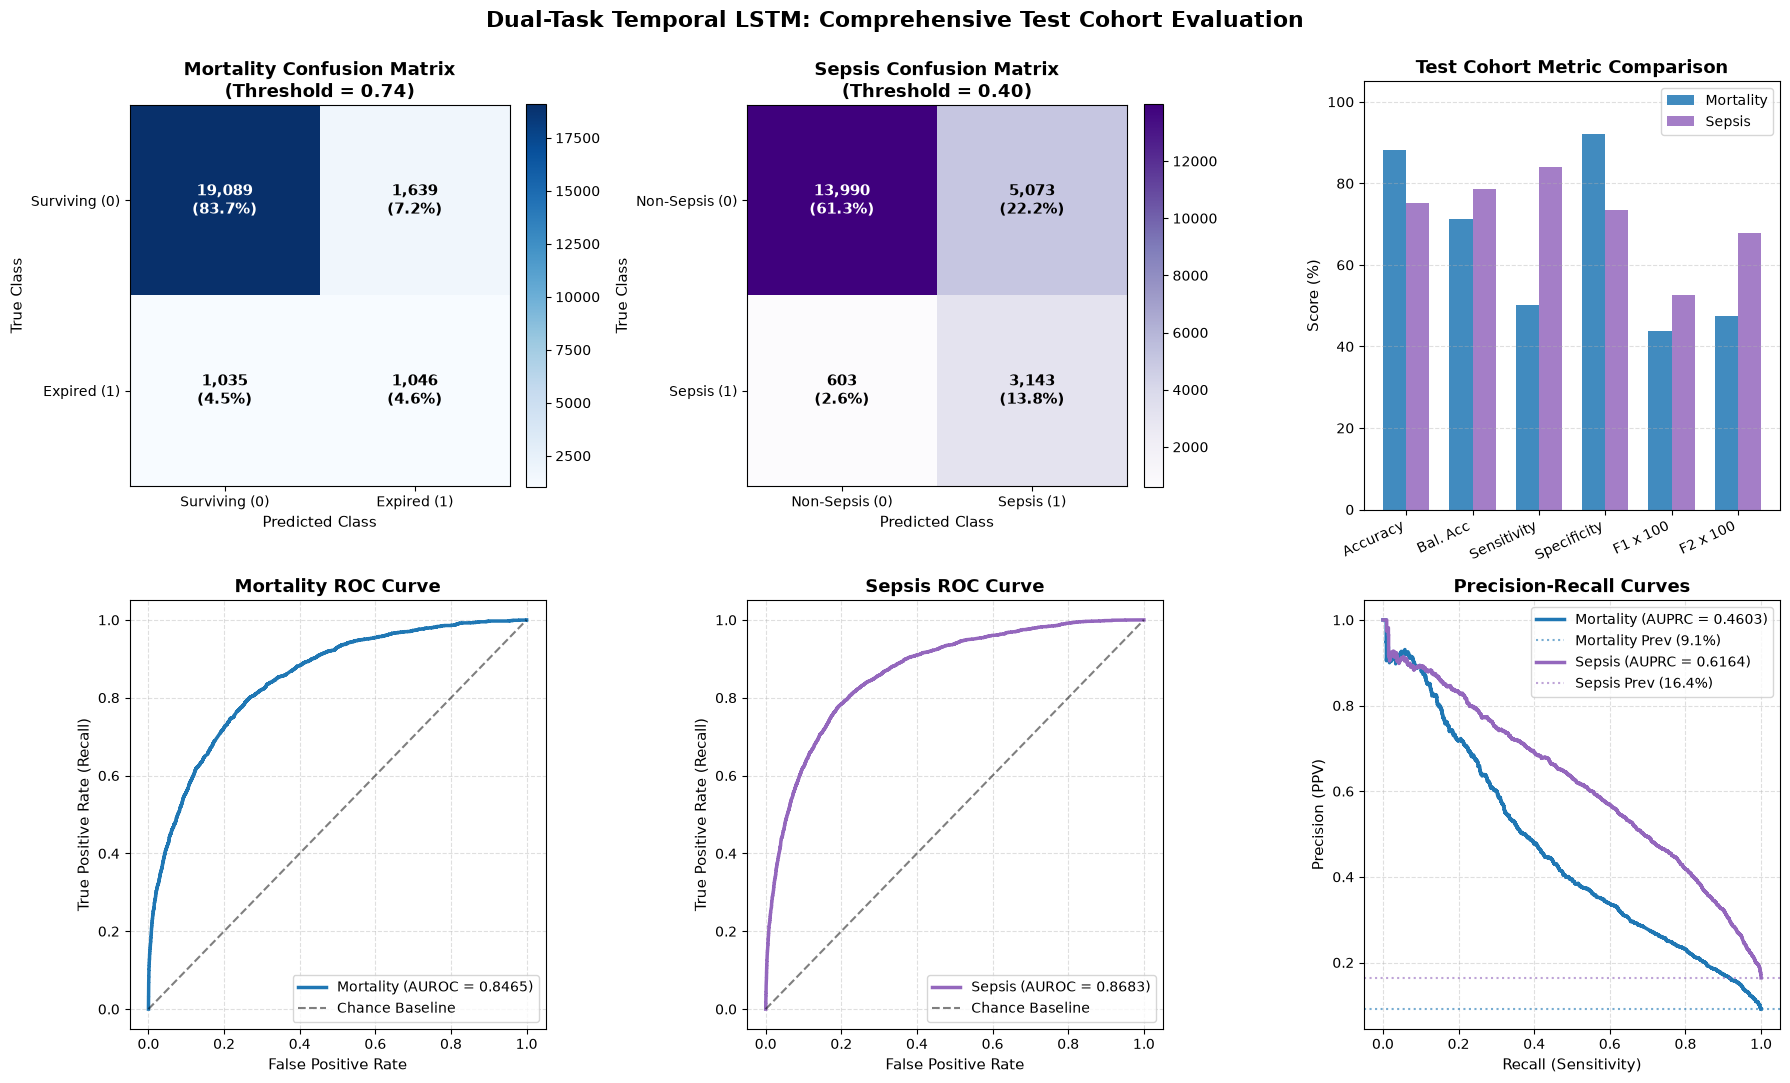

In [15]:
# Create publication-quality evaluation figures
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Dual-Task Temporal LSTM: Comprehensive Test Cohort Evaluation", fontsize=16, fontweight="bold", y=0.98)

# 1. Confusion Matrix: Mortality
cm_m = np.array(mort_test_metrics["Confusion Matrix"])
im0 = axes[0, 0].imshow(cm_m, cmap="Blues", interpolation="nearest")
axes[0, 0].set_title(f"Mortality Confusion Matrix\n(Threshold = {best_thresh_mort:.2f})", fontsize=13, fontweight="semibold")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(["Surviving (0)", "Expired (1)"])
axes[0, 0].set_yticklabels(["Surviving (0)", "Expired (1)"])
axes[0, 0].set_xlabel("Predicted Class", fontsize=11)
axes[0, 0].set_ylabel("True Class", fontsize=11)
for i in range(2):
    for j in range(2):
        count = cm_m[i, j]
        pct = count / cm_m.sum() * 100
        axes[0, 0].text(
            j, i, f"{count:,}\n({pct:.1f}%)", ha="center", va="center",
            color="white" if cm_m[i, j] > cm_m.max() / 2 else "black", fontsize=11, fontweight="bold"
        )
fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

# 2. Confusion Matrix: Sepsis
cm_s = np.array(seps_test_metrics["Confusion Matrix"])
im1 = axes[0, 1].imshow(cm_s, cmap="Purples", interpolation="nearest")
axes[0, 1].set_title(f"Sepsis Confusion Matrix\n(Threshold = {best_thresh_seps:.2f})", fontsize=13, fontweight="semibold")
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_xticklabels(["Non-Sepsis (0)", "Sepsis (1)"])
axes[0, 1].set_yticklabels(["Non-Sepsis (0)", "Sepsis (1)"])
axes[0, 1].set_xlabel("Predicted Class", fontsize=11)
axes[0, 1].set_ylabel("True Class", fontsize=11)
for i in range(2):
    for j in range(2):
        count = cm_s[i, j]
        pct = count / cm_s.sum() * 100
        axes[0, 1].text(
            j, i, f"{count:,}\n({pct:.1f}%)", ha="center", va="center",
            color="white" if cm_s[i, j] > cm_s.max() / 2 else "black", fontsize=11, fontweight="bold"
        )
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# 3. Metric Comparison Bar Chart
metric_labels = ["Accuracy", "Bal. Acc", "Sensitivity", "Specificity", "F1 x 100", "F2 x 100"]
m_vals = [
    mort_test_metrics["Accuracy (%)"], mort_test_metrics["Balanced Accuracy (%)"],
    mort_test_metrics["Sensitivity / Recall (%)"], mort_test_metrics["Specificity (%)"],
    mort_test_metrics["F1-Score"] * 100, mort_test_metrics["F2-Score"] * 100,
]
s_vals = [
    seps_test_metrics["Accuracy (%)"], seps_test_metrics["Balanced Accuracy (%)"],
    seps_test_metrics["Sensitivity / Recall (%)"], seps_test_metrics["Specificity (%)"],
    seps_test_metrics["F1-Score"] * 100, seps_test_metrics["F2-Score"] * 100,
]

x_idx = np.arange(len(metric_labels))
width = 0.35
axes[0, 2].bar(x_idx - width/2, m_vals, width, label="Mortality", color="#1f77b4", alpha=0.85)
axes[0, 2].bar(x_idx + width/2, s_vals, width, label="Sepsis", color="#9467bd", alpha=0.85)
axes[0, 2].set_title("Test Cohort Metric Comparison", fontsize=13, fontweight="semibold")
axes[0, 2].set_xticks(x_idx)
axes[0, 2].set_xticklabels(metric_labels, rotation=25, ha="right", fontsize=10)
axes[0, 2].set_ylabel("Score (%)", fontsize=11)
axes[0, 2].set_ylim(0, 105)
axes[0, 2].legend(frameon=True)
axes[0, 2].grid(axis="y", linestyle="--", alpha=0.4)

# 4. ROC Curves
fpr_m, tpr_m, _ = roc_curve(y_test_mort, test_prob_mort)
fpr_s, tpr_s, _ = roc_curve(y_test_seps, test_prob_seps)
axes[1, 0].plot(fpr_m, tpr_m, color="#1f77b4", lw=2.5, label=f"Mortality (AUROC = {mort_test_metrics['AUROC']:.4f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance Baseline")
axes[1, 0].set_title("Mortality ROC Curve", fontsize=13, fontweight="semibold")
axes[1, 0].set_xlabel("False Positive Rate", fontsize=11)
axes[1, 0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1, 0].legend(loc="lower right", frameon=True)
axes[1, 0].grid(linestyle="--", alpha=0.4)

axes[1, 1].plot(fpr_s, tpr_s, color="#9467bd", lw=2.5, label=f"Sepsis (AUROC = {seps_test_metrics['AUROC']:.4f})")
axes[1, 1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance Baseline")
axes[1, 1].set_title("Sepsis ROC Curve", fontsize=13, fontweight="semibold")
axes[1, 1].set_xlabel("False Positive Rate", fontsize=11)
axes[1, 1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1, 1].legend(loc="lower right", frameon=True)
axes[1, 1].grid(linestyle="--", alpha=0.4)

# 5. Precision-Recall Curves
prec_m, rec_m, _ = precision_recall_curve(y_test_mort, test_prob_mort)
prec_s, rec_s, _ = precision_recall_curve(y_test_seps, test_prob_seps)
prev_m = float(np.mean(y_test_mort))
prev_s = float(np.mean(y_test_seps))

axes[1, 2].plot(rec_m, prec_m, color="#1f77b4", lw=2.5, label=f"Mortality (AUPRC = {mort_test_metrics['AUPRC']:.4f})")
axes[1, 2].axhline(prev_m, color="#1f77b4", linestyle=":", alpha=0.6, label=f"Mortality Prev ({prev_m*100:.1f}%)")
axes[1, 2].plot(rec_s, prec_s, color="#9467bd", lw=2.5, label=f"Sepsis (AUPRC = {seps_test_metrics['AUPRC']:.4f})")
axes[1, 2].axhline(prev_s, color="#9467bd", linestyle=":", alpha=0.6, label=f"Sepsis Prev ({prev_s*100:.1f}%)")
axes[1, 2].set_title("Precision-Recall Curves", fontsize=13, fontweight="semibold")
axes[1, 2].set_xlabel("Recall (Sensitivity)", fontsize=11)
axes[1, 2].set_ylabel("Precision (PPV)", fontsize=11)
axes[1, 2].legend(loc="upper right", frameon=True)
axes[1, 2].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plot_path = FIGURES_DIR / "lstm_dual_task_evaluation.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"Saved diagnostic plots to: {plot_path}")
plt.show()
